# ¿Hasta dónde puede llegar *La bola negra* en taquilla?

En este análisis estimo la recaudación final de *La bola negra* a partir de su acumulado tras siete semanas y del recorrido de otras películas estrenadas en España durante 2026. Mi prioridad es que la predicción sea comprensible, validable y honesta sobre el tamaño de la muestra.

## 1. Preparación

Separo la preparación de los datos del análisis. Los CSV proceden de las páginas semanales y las fichas de Cinerama, que identifican a Comscore Movies como fuente. La descarga se realizó el 10 de noviembre de 2026.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / 'datos'
RESULTS_DIR = BASE_DIR / 'resultados'
RESULTS_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
COLOR = '#446ddf'

In [2]:
weekly = pd.read_csv(DATA_DIR / 'taquilla_semanal_cinerama.csv')
history = pd.read_csv(DATA_DIR / 'historial_completo_peliculas_cinerama.csv')
movies = pd.read_csv(DATA_DIR / 'fichas_peliculas_cinerama.csv')

print(f'{len(weekly):,} filas del top 10 semanal')
print(f'{len(history):,} observaciones semanales completas')
print(f'{history.url_pelicula.nunique()} películas con historial')

411 filas del top 10 semanal
1,137 observaciones semanales completas
108 películas con historial


## 2. Construcción de la muestra

Necesito comparar películas en el mismo momento: justo después de su séptimo fin de semana. Considero terminada una trayectoria cuando la última recaudación semanal observada ya está por debajo de 5.000 euros. Así evito entrenar con películas cuyo total todavía puede crecer de forma apreciable.

In [3]:
months = {'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4, 'mayo': 5, 'junio': 6,
          'julio': 7, 'agosto': 8, 'septiembre': 9, 'octubre': 10,
          'noviembre': 11, 'diciembre': 12}

def parse_date(value):
    # convierto las fechas escritas en castellano
    parts = str(value).lower().split(' de ')
    if len(parts) != 3 or parts[1] not in months:
        return pd.NaT
    return pd.Timestamp(int(parts[2]), months[parts[1]], int(parts[0]))

endings = (history.sort_values(['url_pelicula', 'semana'])
           .groupby('url_pelicula')
           .agg(recaudacion_final_eur=('recaudacion_total_ficha_eur', 'first'),
                ultimo_fin_semana_eur=('recaudacion_fin_semana_eur', 'last'),
                semanas_observadas=('semana', 'max'))
           .reset_index())
movie_fields = movies[['url_pelicula', 'fecha_estreno_texto', 'pais']].copy()
movie_fields['fecha_estreno'] = movie_fields.fecha_estreno_texto.map(parse_date)
week_seven = weekly.loc[weekly.semana == 7].drop_duplicates('url_pelicula')
sample = (week_seven.merge(endings, on='url_pelicula')
          .merge(movie_fields, on='url_pelicula', how='left'))

target_url = 'https://cinerama.es/peliculas/la-bola-negra/'
target = sample.loc[sample.url_pelicula == target_url].iloc[0]
completed = sample.loc[(sample.ultimo_fin_semana_eur <= 5_000)
                       & (sample.url_pelicula != target_url)
                       & sample.fecha_estreno.notna()].sort_values('fecha_estreno').copy()
completed['multiplicador_restante'] = (completed.recaudacion_final_eur
                                         / completed.recaudacion_acumulada_eur)
completed[['titulo', 'recaudacion_acumulada_eur', 'recaudacion_final_eur',
           'multiplicador_restante']]

Out[3]: 
                             titulo  ...  multiplicador_restante
0                            Hamnet  ...                1.095405
1               Cumbres borrascosas  ...                1.020971
2                           Hoppers  ...                1.043319
3               Torrente presidente  ...                1.022676
4                Proyecto Salvación  ...                1.041586
5   Super Mario Galaxy: la película  ...                1.044461
6                           Michael  ...                1.082441
7                         Backrooms  ...                1.023659
8           El Día de la Revelación  ...                1.025204
9                         Obsession  ...                1.123987
10               Minions & Monsters  ...                1.077553
11                           Vaiana  ...                1.027936
13        Spider-Man: Brand New Day  ...                1.026625

[13 rows x 4 columns]


,titulo,recaudacion_acumulada_eur,recaudacion_final_eur,multiplicador_restante
0,Hamnet,6781312,7428281,1.095405
1,Cumbres borrascosas,7516146,7673766,1.020971
2,Hoppers,7562606,7890209,1.043319
3,Torrente presidente,26478396,27078833,1.022676
4,Proyecto Salvación,8869455,9238298,1.041586
5,Super Mario Galaxy: la película,19894688,20779226,1.044461
6,Michael,21784382,23580301,1.082441
7,Backrooms,6322935,6472532,1.023659
8,El Día de la Revelación,7345356,7530492,1.025204
9,Obsession,8476162,9527097,1.123987


La muestra comparable queda en 13 películas. No es grande, así que descarto algoritmos complejos. Utilizo la mediana del crecimiento posterior a la séptima semana: es interpretable y resiste mejor los casos extremos que la media.

count    13.00
mean      5.04
std       3.34
min       2.10
10%       2.29
25%       2.52
50%       4.16
75%       7.76
90%       9.28
max      12.40
Name: multiplicador_restante, dtype: float64


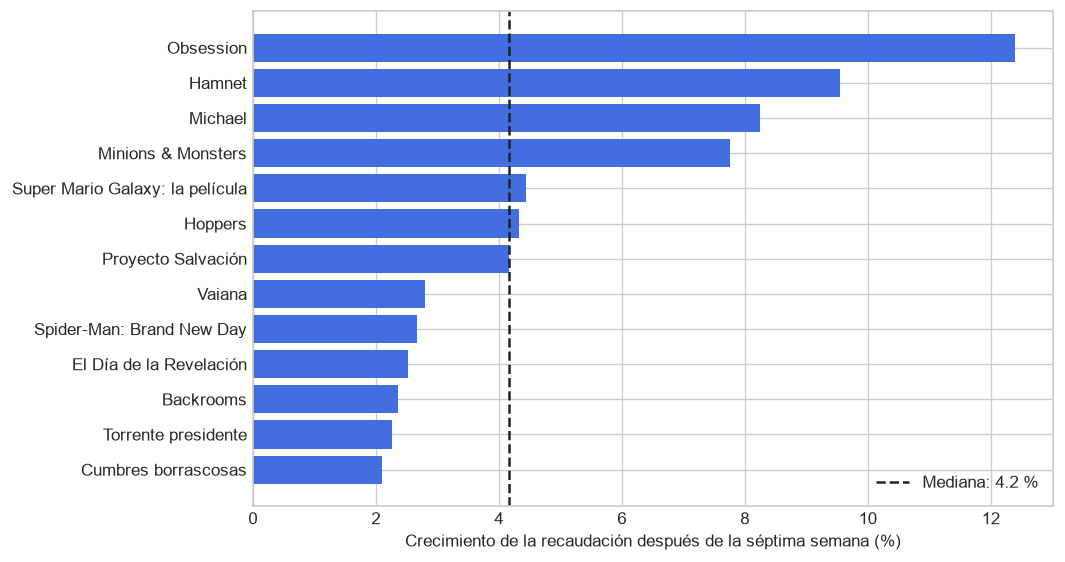

In [4]:
growth_pct = (completed.multiplicador_restante - 1) * 100
print(growth_pct.describe(percentiles=[.1, .25, .5, .75, .9]).round(2))

fig, ax = plt.subplots(figsize=(9, 4.8))
ordered = completed.assign(crecimiento=growth_pct).sort_values('crecimiento')
ax.barh(ordered.titulo, ordered.crecimiento, color=COLOR)
ax.axvline(ordered.crecimiento.median(), color='#222222', linestyle='--',
           label=f"Mediana: {ordered.crecimiento.median():.1f} %")
ax.set_xlabel('Crecimiento de la recaudación después de la séptima semana (%)')
ax.set_ylabel('')
ax.legend()
fig.tight_layout()
plt.show()

## 3. Prueba temporal

Ordeno las películas por fecha de estreno. Entreno con las nueve primeras y reservo las cuatro más recientes para simular una predicción hacia el futuro. Comparo el modelo con una referencia muy conservadora: suponer que, tras la séptima semana, la película no recauda ni un euro más.

In [5]:
train = completed.iloc[:-4].copy()
test = completed.iloc[-4:].copy()
multiplier_train = train.multiplicador_restante.median()
baseline = test.recaudacion_acumulada_eur.to_numpy()
prediction = baseline * multiplier_train
truth = test.recaudacion_final_eur

metrics = pd.DataFrame([
    {'modelo': 'sin crecimiento tras la semana 7',
     'mae_eur': mean_absolute_error(truth, baseline),
     'mape': mean_absolute_percentage_error(truth, baseline)},
    {'modelo': 'multiplicador mediano histórico',
     'mae_eur': mean_absolute_error(truth, prediction),
     'mape': mean_absolute_percentage_error(truth, prediction)},
])
metrics.assign(mae_eur=lambda d: d.mae_eur.round(0),
               mape=lambda d: (d.mape * 100).round(2))

Out[5]: 
                             modelo   mae_eur  mape
0  sin crecimiento tras la semana 7  814169.0  5.88
1   multiplicador mediano histórico  456744.0  3.36


,modelo,mae_eur,mape
0,sin crecimiento tras la semana 7,814169.0,5.88
1,multiplicador mediano histórico,456744.0,3.36


El modelo reduce el error absoluto medio a unos 457.000 euros y el error porcentual al 3,4 % en la prueba. La evaluación solo contiene cuatro películas, por lo que la interpreto como una comprobación mínima, no como una garantía de precisión futura.

In [6]:
test_results = test[['titulo', 'recaudacion_acumulada_eur',
                     'recaudacion_final_eur']].copy()
test_results['prediccion_eur'] = prediction
test_results['error_absoluto_eur'] = abs(test_results.recaudacion_final_eur
                                          - test_results.prediccion_eur)
test_results

Out[6]: 
                       titulo  ...  error_absoluto_eur
9                   Obsession  ...       698447.387112
10         Minions & Monsters  ...       444566.487014
11                     Vaiana  ...       112093.464312
13  Spider-Man: Brand New Day  ...       571868.278415

[4 rows x 5 columns]


,titulo,recaudacion_acumulada_eur,recaudacion_final_eur,prediccion_eur,error_absoluto_eur
9,Obsession,8476162,9527097,8.828650e+06,698447.387112
10,Minions & Monsters,12360326,13318906,1.287434e+07,444566.487014
11,Vaiana,8212270,8441690,8.553783e+06,112093.464312
13,Spider-Man: Brand New Day,38224873,39242615,3.981448e+07,571868.278415


## 4. Predicción para *La bola negra*

Recalculo la mediana con los 13 comparables terminados. Para expresar la incertidumbre utilizo los percentiles 10 y 90 de sus multiplicadores, un intervalo empírico que contiene el 80 % central de los recorridos observados.

In [7]:
multiplier = completed.multiplicador_restante.median()
lower_multiplier, upper_multiplier = completed.multiplicador_restante.quantile([.1, .9])
current = float(target.recaudacion_acumulada_eur)
final_prediction = current * multiplier
lower = current * lower_multiplier
upper = current * upper_multiplier

result = pd.DataFrame([{'recaudacion_actual_eur': current,
                        'prediccion_final_eur': final_prediction,
                        'intervalo_80_inferior_eur': lower,
                        'intervalo_80_superior_eur': upper,
                        'recaudacion_adicional_estimada_eur': final_prediction-current}])
result.round(0)

Out[7]: 
   recaudacion_actual_eur  ...  recaudacion_adicional_estimada_eur
0              38513515.0  ...                           1601614.0

[1 rows x 5 columns]


,recaudacion_actual_eur,prediccion_final_eur,intervalo_80_inferior_eur,intervalo_80_superior_eur,recaudacion_adicional_estimada_eur
0,38513515.0,40115129.0,39394437.0,42088027.0,1601614.0


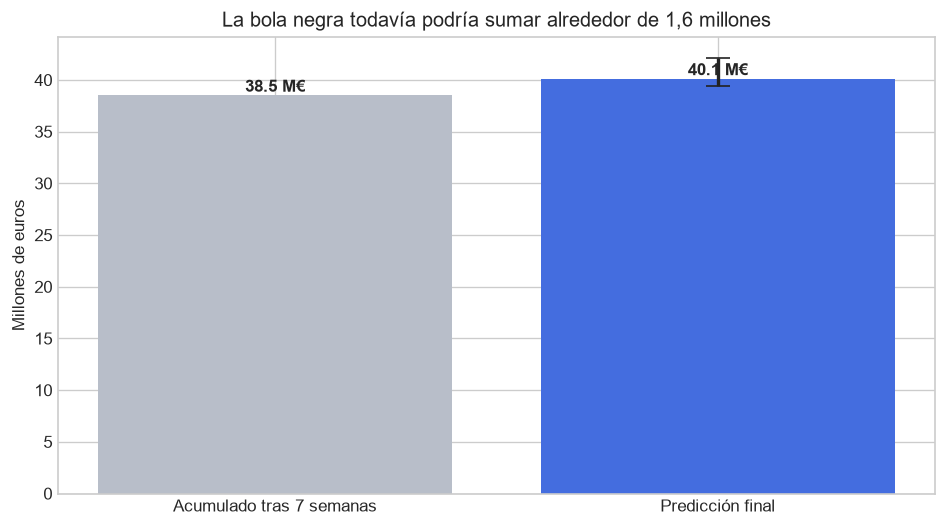

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(['Acumulado tras 7 semanas', 'Predicción final'],
       [current / 1e6, final_prediction / 1e6], color=['#b8bec9', COLOR])
ax.errorbar(1, final_prediction / 1e6,
            yerr=[[final_prediction / 1e6 - lower / 1e6],
                  [upper / 1e6 - final_prediction / 1e6]],
            fmt='none', color='#222222', capsize=7, linewidth=2)
ax.set_ylabel('Millones de euros')
ax.set_title('La bola negra todavía podría sumar alrededor de 1,6 millones')
for index, value in enumerate([current, final_prediction]):
    ax.text(index, value / 1e6 + .35, f'{value/1e6:.1f} M€', ha='center', weight='bold')
fig.tight_layout()
plt.show()

## 5. Conclusión y límites

Mi estimación central es **40,1 millones de euros**, con un intervalo empírico del 80 % entre **39,4 y 42,1 millones**. El modelo espera aproximadamente **1,6 millones adicionales** después del 8 de noviembre.

La principal limitación es la muestra: solo 13 películas de 2026 reúnen un acumulado verificable en la séptima semana y una trayectoria ya terminada. El método tampoco conoce futuros reestrenos, premios, ampliaciones de salas o campañas. Por eso presento el resultado como un rango y no como una cifra segura.

Fuentes: [histórico de taquilla de Cinerama](https://cinerama.es/taquilla/historico/), páginas semanales y fichas de películas; todas identifican a Comscore Movies como origen de las cifras. El contraste institucional se realiza con la [serie semanal del ICAA](https://www.cultura.gob.es/cultura/areas/cine/datos/taquilla-espectadores.html).